# Who is still in the risk set?
### A hands-on Python workshop in competing risks and sampling

We follow a synthetic cohort until **first stroke (fatal or nonfatal)**, **death before
any stroke**, or **censoring**. Through pictures and small experiments, learn why
these endpoints differ, how risk sets work, and how sampling can save expensive
biomarker measurements. This is an educational exercise, **not a medical prediction system**.

**Our visual key:** blue circle = stroke • orange X = death before stroke • grey tick = censored.

**Run:** click ▶ or press **Shift+Enter**. In Colab choose **Runtime → Run all**;
in VS Code/Jupyter choose **Run All**. After changing the top parameters, restart
the runtime/kernel and run from the top to reset all state. Colab needs internet
and a normal free account; nothing here stores credentials or needs payment/GPU.

| Stop | What you will do |
|---|---|
| 0 | Check the environment and set experiment parameters |
| 1 | Simulate eight features; compare CIF with naive 1−KM |
| 2 | Inspect Cox and weighted Fine–Gray risk sets |
| 3 | Draw NCC controls and one case-cohort subcohort |
| 4 | Check a full-risk Fine–Gray objective; explore a tiny optional neural model |
| 5 | Compare measurement budgets and distinguish verified fits from missing methods |

**Scientific status:** the full-risk numerical implementation has explicit verification
checks below. TensorFlow training is opt-in. NCC/CC include optional **conceptual neural prototypes**, not validated sampled
Fine–Gray estimators. Illustrative sampled CIF curves are explicitly labelled unvalidated.


In [97]:
# 0. Setup & environment checks — no installations happen here.
import os
os.environ['CUDA_VISIBLE_DEVICES'] = '-1'  # CPU before importing TensorFlow
os.environ.setdefault('TF_CPP_MIN_LOG_LEVEL', '2')
import sys, platform, importlib, importlib.metadata, time, warnings
IN_COLAB = 'google.colab' in sys.modules
PACKAGES = {'numpy': 'numpy', 'pandas': 'pandas', 'matplotlib': 'matplotlib',
            'scipy': 'scipy', 'sklearn': 'scikit-learn', 'lifelines': 'lifelines'}
missing = []
print('Python', platform.python_version(), '| Colab:', IN_COLAB, '| device: CPU')
for module, package in PACKAGES.items():
    try:
        importlib.import_module(module)
        print(package, importlib.metadata.version(package))
    except (ImportError, OSError) as exc:
        missing.append(package)
        print(package, 'UNAVAILABLE:', str(exc))
for optional in ['tensorflow', 'keras', 'pycmprsk']:
    try:
        print(optional, importlib.metadata.version(optional), '(optional)')
    except importlib.metadata.PackageNotFoundError:
        print(optional, 'not installed (optional)')
print('Missing core packages:', missing or 'none')


Python 3.10.0 | Colab: False | device: CPU
numpy 1.26.4
pandas 2.3.1
matplotlib 3.10.5
scipy 1.11.4
scikit-learn 1.6.1
lifelines 0.30.0
tensorflow 2.20.0 (optional)
keras 3.11.3 (optional)
pycmprsk not installed (optional)
Missing core packages: none


### Optional installation — once per environment
Colab installations belong to the **remote session**, not your laptop, and can be
lost when that session ends. Set `INSTALL_MISSING = True` only if the check above
found missing core packages, then run this cell and the setup check again.
An import failure in an installed package needs investigation; do not blindly upgrade.
TensorFlow is a separate, potentially large download: use a compatible Python runtime
and explicitly install it only if you want the neural exercise. No PyTorch/pycox is needed.


In [98]:
INSTALL_MISSING = False
if INSTALL_MISSING and missing:
    import subprocess
    subprocess.check_call([sys.executable, '-m', 'pip', 'install', *missing])
    importlib.invalidate_caches()
    for module, package in PACKAGES.items():
        importlib.import_module(module)
    print('Core imports passed. Restart if pip changed an already loaded package.')
# Optional large download, deliberately not run automatically:
# %pip install tensorflow


## Config

Use the next cell to choose the cohort, sampling budget, and optional neural training settings. Start with the values shown, then change one setting at a time. After editing, **restart the kernel/runtime and Run All** so every result uses the same configuration.

### Cohort and follow-up

| Setting | What it does |
|---|---|
| `SEED` | Sets the random starting point for reproducible simulated data and model experiments. Keep it fixed when comparing settings; change it to explore another random realization. |
| `FAST_MODE` | Set to `True` for a quicker run: 300 people and 5 neural epochs. `False` uses 800 people and 20 epochs. |
| `N` | Number of people in the full synthetic cohort, before sampling. Larger cohorts take more computation. The expression below chooses this from `FAST_MODE`; you can replace it with an integer of at least 2. |
| `STROKE_RATE` | Baseline rate of first stroke per synthetic year, before feature effects. Increasing it tends to produce earlier/more strokes. Use a positive value. |
| `DEATH_RATE` | Baseline rate of death before stroke per synthetic year, before feature effects. Increasing it tends to produce more competing deaths. Use a positive value. |
| `CENSOR_RATE` | Rate of independent loss to follow-up per synthetic year. Larger values tend to shorten observation; `0` removes this random censoring, but administrative censoring still applies. |
| `ADMIN_TIME` | Maximum follow-up in synthetic years. At `10.0`, anyone with no earlier observed endpoint is censored at 10 years. Use a positive value. |

The rates are **not probabilities**: `STROKE_RATE = 0.07` does not mean a 7% probability of stroke. First-stroke probability also depends on features, follow-up time, and competing death.

### Sampling: who gets an expensive biomarker measurement?

| Setting | What it does |
|---|---|
| `NCC_CONTROLS` | **Nested case-control (NCC):** number of controls requested at each stroke case time. `2` means up to two people still event-free and under observation, excluding that case. Controls are drawn without replacement within a case-time draw; the same person can be selected again at later times or later become a case. Use a nonnegative integer; fewer controls are selected if too few are eligible. |
| `CC_FRACTION` | **Case-cohort (CC):** fraction of the **whole cohort** selected once at baseline. `0.25` means 25%: with `N = 800`, this gives a fixed subcohort of 200 people. All stroke cases outside it are then added, so the total measured sample can exceed 200. People in both groups count only once. Use a value from `0` to `1`; `0` measures stroke cases only and `1` measures everyone. Fractional subcohort sizes are rounded down. |
| `SELECTION_SEED` | Controls random NCC/CC selections separately from cohort generation. Change this alone to select a different sample from the same cohort. `SEED + 1` provides a reproducible starting value. |

**NCC makes new draws at stroke times; CC reuses one baseline draw.** Both designs include all stroke cases. In CC, people who die before stroke or are censored have biomarkers measured only if they belong to the baseline subcohort. More NCC controls or a larger CC fraction generally means more people measured. These settings control sampling, measurement-cost demonstrations, and the optional conceptual neural prototypes below. They do not enable validated sampled Fine–Gray estimators.

### Optional tiny neural model

| Setting | What it does |
|---|---|
| `EPOCHS` | Number of full-training-risk-set updates: 20 normally or 5 in fast mode. More epochs take longer and do not guarantee better predictions. Use a positive integer. |
| `LEARNING_RATE` | Size of the Adam optimizer's training steps. `0.01` is the current value; smaller positive values usually make smaller updates, while overly large values can make training unstable. |
| `TRAIN_NEURAL` | `True` runs the optional full-risk neural exercise when TensorFlow is available and its checks pass. `False` skips neural training. This switch does not install TensorFlow. |

**Try it:** keep `SEED` and `SELECTION_SEED` fixed, change `NCC_CONTROLS` from `2` to `4`, and compare unique people measured. Then restore `2` and change `CC_FRACTION` from `0.25` to `0.10`.

`TRAIN_SAMPLED_PROTOTYPES = True` enables two small conceptual neural fits when `TRAIN_NEURAL` is also `True`. Set it to `False` to keep only the full-risk fitting demonstration. Sampled models report score differences and illustrative CIF curves, not validated CIF prediction error.


In [99]:
# Change these, restart, and Run All.
SEED = 2026
FAST_MODE = False
N = 300 if FAST_MODE else 800
STROKE_RATE, DEATH_RATE, CENSOR_RATE = 0.07, 0.05, 0.035
ADMIN_TIME = 10.0
# Size of the nested case-control control group, as number of controls per case.
NCC_CONTROLS = 2
# Fraction of the whole cohort drawn once at baseline; add all stroke cases outside it.
CC_FRACTION = 0.25
SELECTION_SEED = SEED + 1
EPOCHS = 5 if FAST_MODE else 20
LEARNING_RATE = 0.01
TRAIN_NEURAL = True
TRAIN_SAMPLED_PROTOTYPES = True  # Didactic scores only; requires TRAIN_NEURAL.


In [100]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib.lines import Line2D
from matplotlib.patches import Rectangle
from scipy.special import logsumexp
from scipy.optimize import minimize
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from lifelines import AalenJohansenFitter, KaplanMeierFitter, CoxPHFitter
from IPython.display import display

FEATURES = [f'X{i}' for i in range(1, 9)]
COLORS = {0: '#707070', 1: '#0072B2', 2: '#D55E00'}
MARKERS = {0: '|', 1: 'o', 2: 'x'}
LABELS = {0: 'Censored', 1: 'Stroke', 2: 'Death before stroke'}
plt.rcParams.update({'figure.figsize': (9, 4.5), 'font.size': 11,
                     'axes.spines.top': False, 'axes.spines.right': False})
def event_legend():
    return [Line2D([0], [0], color=COLORS[e], marker=MARKERS[e],
                   linestyle='', label=LABELS[e], markersize=9) for e in [1, 2, 0]]
def context(extra=''):
    print(f'seed={SEED}; n={N}; rates(stroke, death, censor)='
          f'{STROKE_RATE, DEATH_RATE, CENSOR_RATE}; admin={ADMIN_TIME}; {extra}')
def probability_axes(ax):
    ax.set(xlabel='Follow-up time (synthetic years)',
           ylabel='Probability of first stroke by time t', ylim=(0, 1))


## 1. What happened first?
Our eight synthetic inputs are four continuous measurements and four binary factors.
Independent exponential clocks **conditional on these inputs** generate stroke and death;
independent censoring and an administrative end date limit observation. Censoring is an
observation process, not a clinical event. A fatal stroke is still coded as **stroke**.

The simulator returns observed data separately from the generating rates. Those rates
give a truth benchmark, not extra information available to fitted models.
The generating cause-specific coefficients are **not true Fine–Gray coefficients**.


In [101]:
def simulate_cohort(n=800, seed=2026, stroke_rate=.07, death_rate=.05,
                    censor_rate=.035, admin_time=10.):
    """Eight observed features; latent rates kept in a separate truth table."""
    if n < 2 or min(stroke_rate, death_rate, admin_time) <= 0 or censor_rate < 0:
        raise ValueError('Use n >= 2, positive event rates/end time, nonnegative censoring.')
    rng = np.random.default_rng(seed)
    x = np.column_stack([rng.normal(size=(n, 4)), rng.binomial(1, .5, (n, 4))])
    b1 = np.array([.35, -.25, .15, .10, .30, -.20, .15, .10])
    b2 = np.array([-.15, .30, .10, -.20, .15, .25, -.10, .20])
    rate1, rate2 = stroke_rate*np.exp(x@b1), death_rate*np.exp(x@b2)
    clocks = np.column_stack([rng.exponential(1/rate1), rng.exponential(1/rate2),
              rng.exponential(1/censor_rate, n) if censor_rate else np.full(n, np.inf),
              np.full(n, admin_time)])
    first = clocks.argmin(axis=1)
    df = pd.DataFrame(x, columns=FEATURES)
    df.insert(0, 'event', np.choose(first, [1, 2, 0, 0]))
    df.insert(0, 'time', clocks.min(axis=1))
    df.insert(0, 'subject_id', np.arange(n))
    truth = pd.DataFrame({'subject_id': np.arange(n), 'stroke_rate': rate1, 'death_rate': rate2})
    return df, truth

def true_cif(truth, times, cause=1):
    """Rows: people; columns: times. No censoring in the underlying probability."""
    a = truth.stroke_rate.to_numpy()[:, None]
    b = truth.death_rate.to_numpy()[:, None]
    return (a if cause == 1 else b)/(a+b)*(-np.expm1(-(a+b)*np.asarray(times)))


seed=2026; n=800; rates(stroke, death, censor)=(0.07, 0.05, 0.035); admin=10.0; 


,endpoint,count,fraction
0,Censored,244,0.3050
1,Stroke,314,0.3925
2,Death before stroke,242,0.3025


,subject_id,time,event,X1,X5
1,1,0.652,1,0.638,0.0
2,2,1.253,1,-0.268,0.0
3,3,2.439,1,-0.064,0.0
0,0,2.446,0,-0.793,0.0
4,4,4.094,1,-0.404,0.0
16,16,4.805,2,-0.913,1.0
5,5,5.721,0,-0.477,0.0
7,7,5.994,2,-1.230,1.0
15,15,6.343,2,-0.985,1.0
13,13,7.568,2,-0.664,1.0


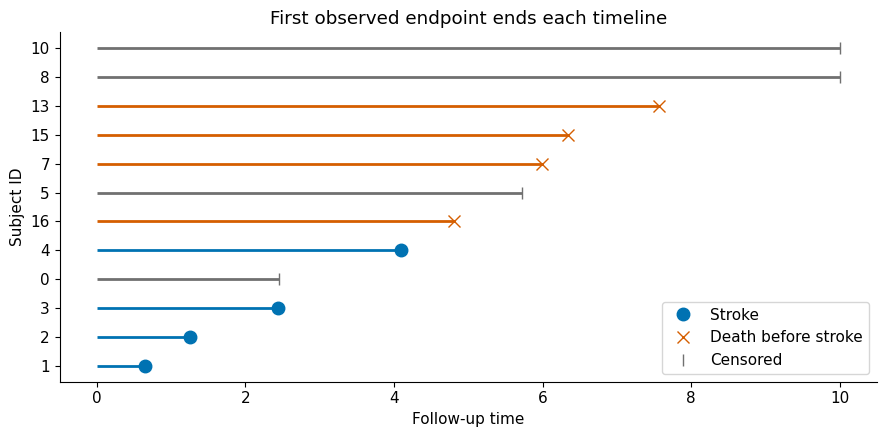

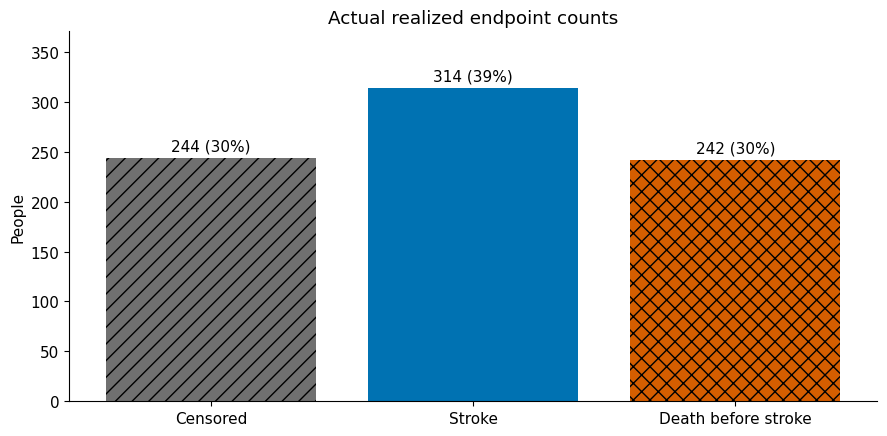

In [102]:
cohort, population_truth = simulate_cohort(N, SEED, STROKE_RATE, DEATH_RATE,
                                          CENSOR_RATE, ADMIN_TIME)
context()
counts = cohort.event.value_counts().reindex([0, 1, 2], fill_value=0)
display(pd.DataFrame({'endpoint': [LABELS[e] for e in counts.index],
                      'count': counts.values, 'fraction': counts.values/N}))
if min(counts[1], counts[2]) < 10:
    print('Sparse events: increase N or event rates before fitting models.')
# Handpicked examples span endpoint types while retaining real simulated times.
toy = pd.concat([cohort[cohort.event == e].head(4) for e in [1, 2, 0]]).sort_values('time')
display(toy[['subject_id', 'time', 'event', 'X1', 'X5']].round(3))
fig, ax = plt.subplots()
for y, row in enumerate(toy.itertuples()):
    ax.hlines(y, 0, row.time, color=COLORS[row.event], lw=2)
    ax.plot(row.time, y, marker=MARKERS[row.event], color=COLORS[row.event], ms=9)
ax.set(yticks=range(len(toy)), yticklabels=toy.subject_id, xlabel='Follow-up time',
       ylabel='Subject ID', title='First observed endpoint ends each timeline')
ax.legend(handles=event_legend(), loc='lower right')
plt.tight_layout(); plt.show()
fig, ax = plt.subplots()
bars = ax.bar([LABELS[e] for e in counts.index], counts, color=[COLORS[e] for e in counts.index])
for bar, e in zip(bars, counts.index):
    bar.set_hatch({0: '//', 1: '', 2: 'xx'}[e])
ax.bar_label(bars, labels=[f'{v} ({v/N:.0%})' for v in counts], padding=3)
ax.set(ylabel='People', title='Actual realized endpoint counts', ylim=(0, max(counts)*1.18))
plt.tight_layout(); plt.show()


**Try it:** choose one subject. What happened first? Could an orange X later become
a first stroke? Change `DEATH_RATE`, restart and run again. How do the counts change?

### Probability of stroke: two curves answering different questions
The **Aalen–Johansen CIF** estimates observed-world first-stroke probability.
The naive complement of Kaplan–Meier treats competing death as censored and does
not estimate that probability. This does **not** make cause-specific Cox regression invalid.
Our continuous clocks avoid event ties; shared administrative censoring is allowed.
If event-time ties occur, we report them instead of silently accepting random jitter.


seed=2026; n=800; rates(stroke, death, censor)=(0.07, 0.05, 0.035); admin=10.0; CIF comparison; no confidence bands requested


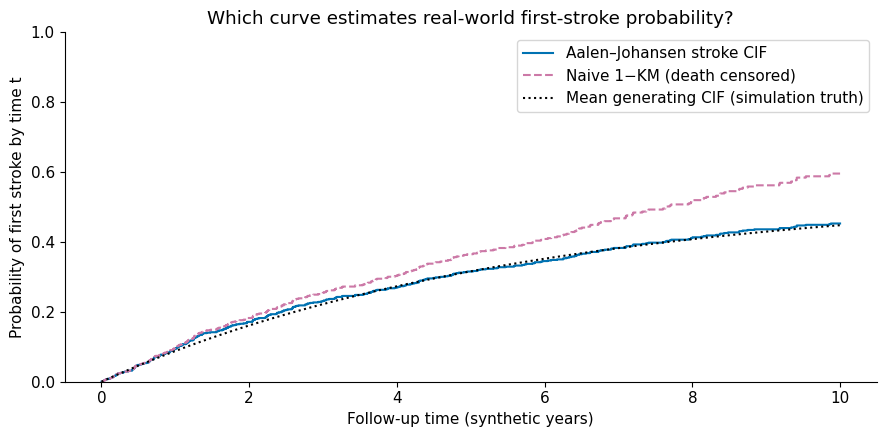

In [103]:
context('CIF comparison; no confidence bands requested')
fig, ax = plt.subplots()
has_event_ties = cohort.loc[cohort.event != 0, 'time'].duplicated().any()
if has_event_ties:
    print('Event ties detected: Aalen–Johansen panel skipped; review tie handling first.')
elif counts[1]:
    aj = AalenJohansenFitter(calculate_variance=False, seed=SEED)
    aj.fit(cohort.time, cohort.event, event_of_interest=1)
    ax.step(aj.cumulative_density_.index, aj.cumulative_density_.iloc[:, 0],
            where='post', color=COLORS[1], label='Aalen–Johansen stroke CIF')
km = KaplanMeierFitter().fit(cohort.time, cohort.event == 1)
ax.step(km.survival_function_.index, 1-km.survival_function_.iloc[:, 0],
        where='post', color='#CC79A7', linestyle='--', label='Naive 1−KM (death censored)')
grid = np.linspace(0, ADMIN_TIME, 101)
ax.plot(grid, true_cif(population_truth, grid).mean(axis=0), ':', color='black',
        label='Mean generating CIF (simulation truth)')
probability_axes(ax); ax.set_title('Which curve estimates real-world first-stroke probability?')
ax.legend(); plt.tight_layout(); plt.show()


**Try it:** increase the death rate. Why can the gap widen? The dotted curve is the
average conditional generating truth, not a fitted model or a confidence limit.

## 2. Who contributes at a stroke time?
A risk set describes contributions **just before** a failure. Cause-specific Cox
uses people still event-free and observed. Fine–Gray retains earlier competing deaths
in a **constructed** set: mathematical bookkeeping, not biological eligibility.

Let $G(t-)$ be the estimated probability of remaining uncensored just before $t$.
A prior death at $s<t$ contributes $G(t-)/G(s-)$; an event-free observed person
contributes 1. Earlier stroke/censoring contributes 0. These are **censoring retention
weights**, not probabilities of stroke and not sampling inclusion weights.

For example, $0.72/0.90=0.80$. With no censoring the contribution is 1.
We use a marginal censoring KM: this requires independent censoring as in our generator.
No delayed entry or time-varying covariates are supported.


In [104]:
def censor_survival_left(df, query):
    """Reverse KM, evaluated strictly before query; outcomes censor the censoring clock."""
    times = df.time.to_numpy(float)
    event = df.event.to_numpy(int)
    unique = np.unique(times)
    factors = np.array([1 - np.sum((times == t) & (event == 0))/np.sum(times >= t)
                        for t in unique])
    after = np.cumprod(factors)
    index = np.searchsorted(unique, np.asarray(query), side='left')
    return np.r_[1., after][index]

def risk_weights(df, t):
    """Observed just-before-t contribution, with normalized competing-death retention."""
    times, event = df.time.to_numpy(float), df.event.to_numpy(int)
    w = (times >= t).astype(float)
    retained = (times < t) & (event == 2)
    if retained.any():
        gs = censor_survival_left(df, times[retained])
        gt = float(censor_survival_left(df, t))
        if np.any(gs <= 0) or gt < .05:
            raise ValueError('Censoring support too small: shorten the fitting horizon.')
        w[retained] = gt/gs
    return w

def risk_table(df, t):
    w = risk_weights(df, t)
    active = df.time.to_numpy() >= t
    reason = np.where(active, 'Observed/event-free just before t',
             np.where(df.event == 2, 'Earlier death: retained bookkeeping',
             np.where(df.event == 1, 'Earlier stroke: removed', 'Earlier censoring: removed')))
    return pd.DataFrame({'subject_id': df.subject_id.to_numpy(), 'time': df.time.to_numpy(),
           'endpoint': df.event.map(LABELS).to_numpy(), 'Cox included': active,
           'FG member': active | (df.event.to_numpy() == 2),
           'FG contribution': w, 'reason': reason})


Handcrafted teaching cohort; selected stroke time=5.0; step=1


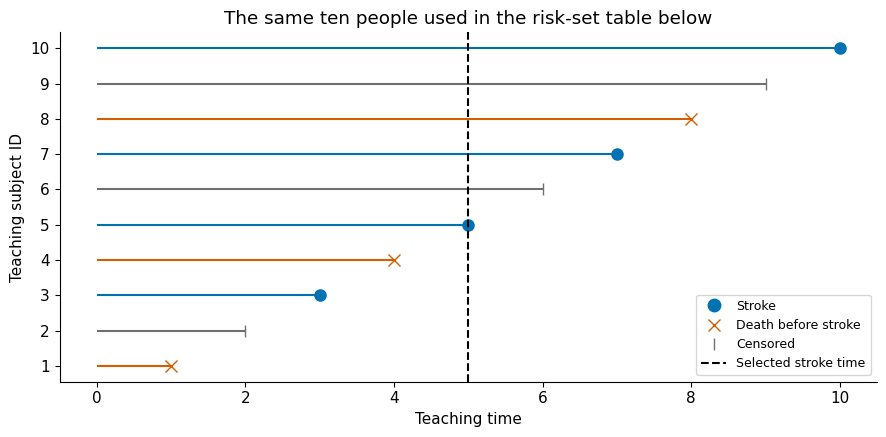

,subject_id,time,endpoint,Cox included,FG member,FG contribution,reason
0,1,1.0,Death before stroke,False,True,0.889,Earlier death: retained bookkeeping
1,2,2.0,Censored,False,False,0.000,Earlier censoring: removed
2,3,3.0,Stroke,False,False,0.000,Earlier stroke: removed
3,4,4.0,Death before stroke,False,True,1.000,Earlier death: retained bookkeeping
4,5,5.0,Stroke,True,True,1.000,Observed/event-free just before t
5,6,6.0,Censored,True,True,1.000,Observed/event-free just before t
6,7,7.0,Stroke,True,True,1.000,Observed/event-free just before t
7,8,8.0,Death before stroke,True,True,1.000,Observed/event-free just before t
8,9,9.0,Censored,True,True,1.000,Observed/event-free just before t
9,10,10.0,Stroke,True,True,1.000,Observed/event-free just before t


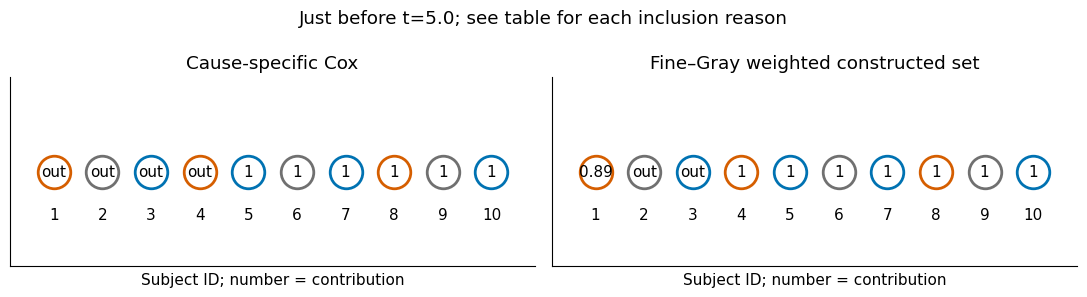

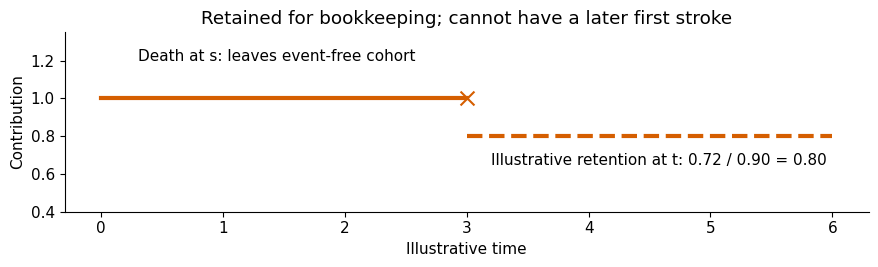

In [105]:
# An explicit teaching cohort ensures all four before-t states are visible.
teaching = pd.DataFrame({'subject_id': np.arange(1, 11),
                        'time': [1., 2., 3., 4., 5., 6., 7., 8., 9., 10.],
                        'event': [2, 0, 1, 2, 1, 0, 1, 2, 0, 1]})
STROKE_STEP = 1  # 0, 1, 2, 3; rerun this cell to step through stroke times
stroke_times = teaching.loc[teaching.event == 1, 'time'].to_numpy()
t_selected = stroke_times[np.clip(STROKE_STEP, 0, len(stroke_times)-1)]
print(f'Handcrafted teaching cohort; selected stroke time={t_selected}; step={STROKE_STEP}')
fig, ax = plt.subplots()
for y, row in enumerate(teaching.itertuples()):
    ax.hlines(y, 0, row.time, color=COLORS[row.event])
    ax.plot(row.time, y, marker=MARKERS[row.event], color=COLORS[row.event], ms=8)
ax.axvline(t_selected, color='black', linestyle='--', label='Selected stroke time')
ax.set(yticks=range(len(teaching)), yticklabels=teaching.subject_id,
       xlabel='Teaching time', ylabel='Teaching subject ID', title='The same ten people used in the risk-set table below')
ax.legend(handles=event_legend()+[Line2D([0], [0], color='black', linestyle='--', label='Selected stroke time')],
          loc='lower right', fontsize=9)
plt.tight_layout(); plt.show()
display(risk_table(teaching, t_selected).round(3))
fig, axes = plt.subplots(1, 2, figsize=(11, 3), sharey=True)
tab = risk_table(teaching, t_selected)
for ax, col, title in zip(axes, ['Cox included', 'FG contribution'],
                           ['Cause-specific Cox', 'Fine–Gray weighted constructed set']):
    for i, row in enumerate(teaching.itertuples()):
        contribution = float(tab.iloc[i][col])
        ax.scatter(i, 0, s=550, facecolors='white', edgecolors=COLORS[row.event], lw=2)
        ax.text(i, 0, f'{contribution:.2g}' if contribution else 'out', ha='center', va='center')
        ax.text(i, -.3, str(row.subject_id), ha='center')
    ax.set(xlim=(-.9, 9.9), ylim=(-.6, .6), title=title, xlabel='Subject ID; number = contribution')
    ax.set_xticks([]); ax.set_yticks([])
fig.suptitle(f'Just before t={t_selected}; see table for each inclusion reason')
plt.tight_layout(); plt.show()
fig, ax = plt.subplots(figsize=(9, 2.8))
ax.plot([0, 3], [1, 1], color=COLORS[2], lw=3)
ax.plot([3, 6], [.8, .8], '--', color=COLORS[2], lw=3)
ax.scatter([3], [1], marker='x', s=100, color=COLORS[2])
ax.annotate('Death at s: leaves event-free cohort', (3, 1), xytext=(.3, 1.2))
ax.text(3.2, .65, 'Illustrative retention at t: 0.72 / 0.90 = 0.80')
ax.set(xlabel='Illustrative time', ylabel='Contribution', ylim=(.4, 1.35),
       title='Retained for bookkeeping; cannot have a later first stroke')
plt.tight_layout(); plt.show()


**Try it:** move `STROKE_STEP`. Explain why subject 1 remains in Fine–Gray and why
subject 2 does not. The orange dashed segment is an illustrative weight at a later
time, not the full estimated time-varying weight trajectory.

### Fit a cause-specific Cox model
For stroke regression, recode other endpoints as censored. This legitimately estimates
the stroke cause-specific hazard. Its hazard ratio is **not** a probability ratio.
To obtain a stroke CIF from cause-specific models, both stroke and death hazards are
needed; `1−S_stroke` alone is insufficient.

We create a common subject-level holdout now. Scaling and all subsequent model/censoring
fitting use only training data. Sampling visuals later describe the whole source cohort
but never feed a sampled estimator or tune against the holdout.


In [106]:
strata = cohort.event if cohort.event.value_counts().min() >= 2 else None
train_ids, test_ids = train_test_split(np.arange(N), test_size=.25, random_state=SEED+2,
                                     stratify=strata)
train, test = cohort.iloc[train_ids].copy(), cohort.iloc[test_ids].copy()
scaler = StandardScaler().fit(train[FEATURES])
x_train, x_test = scaler.transform(train[FEATURES]), scaler.transform(test[FEATURES])
context(f'train={len(train)}, untouched holdout={len(test)}')
if (train.event == 1).sum() >= 15 and all(train[FEATURES].nunique() > 1):
    cox_data = train[FEATURES + ['time']].copy()
    cox_data['stroke'] = train.event == 1
    try:
        cox = CoxPHFitter(penalizer=.01).fit(cox_data, 'time', 'stroke')
        display(cox.summary[['coef', 'exp(coef)']].rename(columns={'exp(coef)': 'cause-specific HR'}))
        print('Small ridge penalty 0.01 for stability; descriptive teaching fit, no p-values.')
    except Exception as exc:
        print('Cox skipped: fitting failed on this configuration:', str(exc))
else:
    print('Cox skipped: insufficient strokes or constant features; increase N.')


seed=2026; n=800; rates(stroke, death, censor)=(0.07, 0.05, 0.035); admin=10.0; train=600, untouched holdout=200


,coef,cause-specific HR
covariate,,
X1,0.388816,1.475233
X2,-0.169319,0.844240
X3,0.087452,1.091390
X4,0.048377,1.049567
X5,0.137480,1.147379
X6,-0.206290,0.813597
X7,0.101614,1.106956
X8,0.020701,1.020916


Small ridge penalty 0.01 for stability; descriptive teaching fit, no p-values.


## 3. Who needs an expensive biomarker measurement?
All source-cohort IDs, outcome times and endpoint types are known. Imagine the eight
inputs are expensive assays: a sampling design permits access only for selected people.

**NCC:** at each stroke time, draw up to `m` event-free, observed controls uniformly
**without replacement within that time**. Exclude the case. A person may reappear
at different times or later become a case. This source set is **not** the Fine–Gray
constructed set. `m / eligible_count` is a per-draw probability, not the probability
of ever being measured.

**Case-cohort:** draw one fixed-size random baseline subcohort, then add all stroke
cases. Competing-death and censored people outside the subcohort are not measured
unless they satisfy the stated inclusion rule (which here adds only stroke cases).
Actual baseline inclusion probability is `k/n` after rounding, not the nominal fraction.


In [107]:
def sample_ncc(outcomes, m=2, seed=2027):
    """Takes outcomes only, never biomarker columns. No replacement within a risk set."""
    if not isinstance(m, (int, np.integer)) or m < 0:
        raise ValueError('m must be a nonnegative integer')
    rng = np.random.default_rng(seed)
    records = []
    for case in outcomes[outcomes.event == 1].sort_values('time').itertuples():
        eligible = outcomes.loc[(outcomes.time >= case.time) &
                                (outcomes.subject_id != case.subject_id), 'subject_id'].to_numpy()
        k = min(m, len(eligible))
        chosen = rng.choice(eligible, k, replace=False)
        records.append({'case_id': case.subject_id, 'time': case.time,
                        'eligible': eligible, 'chosen': chosen,
                        'per_draw_probability': k/len(eligible) if len(eligible) else np.nan})
    cases = set(outcomes.loc[outcomes.event == 1, 'subject_id'])
    controls = {int(i) for r in records for i in r['chosen']}
    return {'records': records, 'cases': cases, 'controls': controls,
            'measured': cases | controls, 'control_occurrences': sum(len(r['chosen']) for r in records)}

def sample_case_cohort(outcomes, q=.25, seed=2027):
    """One fixed baseline SRS; all stroke cases added exactly once."""
    if not 0 <= q <= 1:
        raise ValueError('q must lie in [0, 1]')
    k = int(np.floor(q*len(outcomes)))
    # One random ordering makes fraction experiments nested for a fixed seed.
    baseline = set(np.random.default_rng(seed).permutation(outcomes.subject_id)[:k])
    cases = set(outcomes.loc[outcomes.event == 1, 'subject_id'])
    return {'baseline': baseline, 'cases': cases, 'added': cases-baseline,
            'measured': baseline | cases, 'q_actual': k/len(outcomes)}

def measured_view(df, selected):
    """Enforce the measurement boundary: unmeasured covariates become missing."""
    observed = df.copy()
    observed.loc[~observed.subject_id.isin(selected), FEATURES] = np.nan
    return observed

def sampling_summary(outcomes, ncc, cc):
    n = len(outcomes)
    deaths = set(outcomes.loc[outcomes.event == 2, 'subject_id'])
    cases = int((outcomes.event == 1).sum())
    rows = []
    for mode, measured, selected, occurrences in [
        ('Full cohort', set(outcomes.subject_id), n, n),
        ('NCC', ncc['measured'], len(ncc['controls']), cases+ncc['control_occurrences']),
        ('Case-cohort', cc['measured'], len(cc['baseline']), len(cc['baseline'])+cases)]:
        rows.append({'design': mode, 'stroke cases': cases, 'controls/subcohort': selected,
                     'selection occurrences': occurrences, 'unique measured': len(measured),
                     'fraction measured': len(measured)/n, 'deaths with assays': len(measured & deaths)})
    return pd.DataFrame(rows)


seed=2026; n=800; rates(stroke, death, censor)=(0.07, 0.05, 0.035); admin=10.0; m=2; q=0.25; actual q=0.250; selection seed=2027


,design,stroke cases,controls/subcohort,selection occurrences,unique measured,fraction measured,deaths with assays
0,Full cohort,314,800,800,800,1.000,242
1,NCC,314,379,942,569,0.711,106
2,Case-cohort,314,200,514,440,0.550,70


CC selection occurrences count baseline draws plus case ascertainments, including overlap.
NCC unique controls may include people who later became stroke cases.


,subject_id,event,X1,X5
0,0,0,NaN,NaN
1,1,1,0.638295,0.0
2,2,1,-0.267660,0.0
3,3,1,-0.064128,0.0
4,4,1,-0.403750,0.0
5,5,0,-0.477279,0.0
6,6,1,0.641837,0.0
7,7,2,NaN,NaN


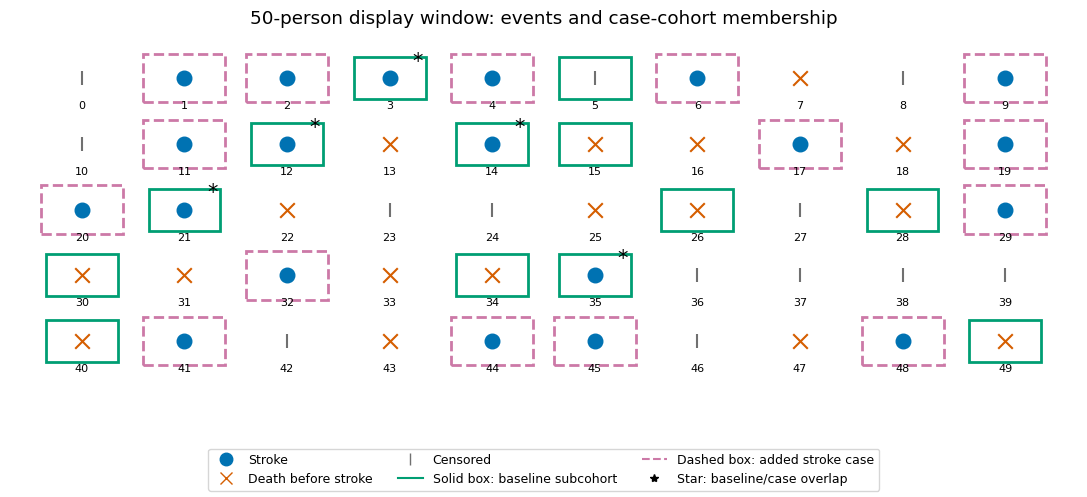

In [108]:
outcomes = cohort[['subject_id', 'time', 'event']]
ncc = sample_ncc(outcomes, NCC_CONTROLS, SELECTION_SEED)
cc = sample_case_cohort(outcomes, CC_FRACTION, SELECTION_SEED)
ncc_observed, cc_observed = measured_view(cohort, ncc['measured']), measured_view(cohort, cc['measured'])
context(f'm={NCC_CONTROLS}; q={CC_FRACTION}; actual q={cc["q_actual"]:.3f}; selection seed={SELECTION_SEED}')
display(sampling_summary(outcomes, ncc, cc).round(3))
print('CC selection occurrences count baseline draws plus case ascertainments, including overlap.')
print('NCC unique controls may include people who later became stroke cases.')
display(cc_observed[['subject_id', 'event', 'X1', 'X5']].head(8))

# First 50 people are a display window into the SAME full-cohort draw.
tiles = cohort.head(50)
fig, ax = plt.subplots(figsize=(11, 5))
for i, row in enumerate(tiles.itertuples()):
    x, y = i % 10, -(i // 10)
    ax.scatter(x, y, color=COLORS[row.event], marker=MARKERS[row.event], s=110)
    if row.subject_id in cc['baseline']:
        ax.add_patch(Rectangle((x-.35, y-.32), .7, .64, fill=False, edgecolor='#009E73', lw=2))
    if row.subject_id in cc['added']:
        ax.add_patch(Rectangle((x-.4, y-.37), .8, .74, fill=False, edgecolor='#CC79A7', lw=2, linestyle='--'))
    if row.subject_id in cc['baseline'] & cc['cases']:
        ax.text(x+.22, y+.16, '*', fontsize=15)
    ax.text(x, y-.47, str(row.subject_id), ha='center', fontsize=8)
ax.set(xlim=(-.7, 9.7), ylim=(-5, .7), title='50-person display window: events and case-cohort membership')
ax.axis('off')
fig.legend(handles=event_legend()+[
    Line2D([0], [0], color='#009E73', label='Solid box: baseline subcohort'),
    Line2D([0], [0], color='#CC79A7', linestyle='--', label='Dashed box: added stroke case'),
    Line2D([0], [0], color='black', marker='*', linestyle='', label='Star: baseline/case overlap')],
    loc='lower center', ncol=3, fontsize=9)
plt.tight_layout(rect=(0, .14, 1, 1)); plt.show()


seed=2026; n=800; rates(stroke, death, censor)=(0.07, 0.05, 0.035); admin=10.0; NCC step index=2; m=2; selection seed=2027
Draw 3 (index 2): case 127 at t=0.03261
800 people − 3 earlier endpoints − 1 current case = 796 eligible controls; 2 selected.
Chosen IDs: [380, 397]; control selections so far: 6; unique controls so far: 6.
Earlier endpoints excluded from this draw (first 10 shown):


,subject_id,time,endpoint
565,565,0.014288,Censored
441,441,0.016288,Stroke
716,716,0.028037,Stroke


Controls are eligible now; a selected control may later become a stroke case.


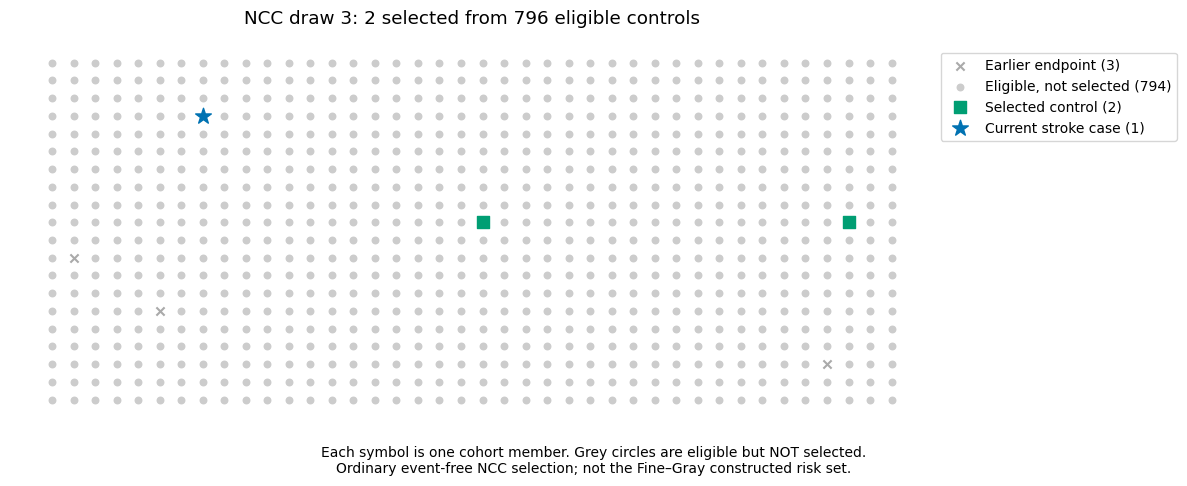

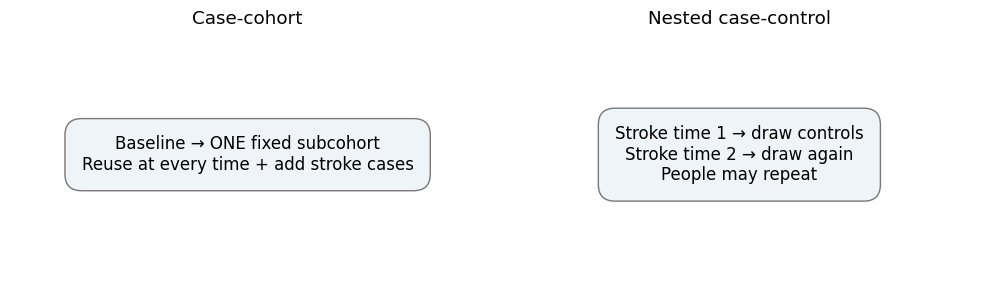

In [109]:
# Zero-based index: 0 = first draw, 1 = second, 2 = third.
NCC_STEP = 2
context(f'NCC step index={NCC_STEP}; m={NCC_CONTROLS}; selection seed={SELECTION_SEED}')
if ncc['records']:
    step = int(np.clip(NCC_STEP, 0, len(ncc['records'])-1))
    rec = ncc['records'][step]
    draws_so_far = ncc['records'][:step+1]
    cumulative = {int(i) for r in draws_so_far for i in r['chosen']}
    occurrences = sum(len(r['chosen']) for r in draws_so_far)
    earlier = cohort.loc[cohort.time < rec['time'], ['subject_id', 'time', 'event']]
    print(f'Draw {step+1} (index {step}): case {rec["case_id"]} at t={rec["time"]:.5f}')
    print(f'{len(cohort)} people − {len(earlier)} earlier endpoints − 1 current case '
          f'= {len(rec["eligible"])} eligible controls; {len(rec["chosen"])} selected.')
    print(f'Chosen IDs: {rec["chosen"].tolist()}; control selections so far: {occurrences}; '
          f'unique controls so far: {len(cumulative)}.')
    if len(earlier):
        print('Earlier endpoints excluded from this draw (first 10 shown):')
        display(earlier.sort_values('time').head(10).assign(
            endpoint=lambda d: d.event.map(LABELS)).drop(columns='event'))
    print('Controls are eligible now; a selected control may later become a stroke case.')
    # Exclusive display categories: chosen controls are a subset of the eligible pool.
    status = np.full(len(cohort), 'Earlier endpoint', dtype=object)
    status[cohort.subject_id.isin(rec['eligible'])] = 'Eligible, not selected'
    status[cohort.subject_id.isin(rec['chosen'])] = 'Selected control'
    status[cohort.subject_id == rec['case_id']] = 'Current stroke case'
    fig, ax = plt.subplots(figsize=(12, 5))
    styles = {'Earlier endpoint': ('#aaaaaa', 'x', 35),
              'Eligible, not selected': ('#cccccc', 'o', 22),
              'Selected control': ('#009E73', 's', 85),
              'Current stroke case': (COLORS[1], '*', 140)}
    for label, (color, marker, size) in styles.items():
        pos = np.flatnonzero(status == label)
        ax.scatter(pos % 40, -(pos // 40), c=color, marker=marker, s=size,
                   label=f'{label} ({len(pos)})', zorder=3 if size > 50 else 1)
    ax.axis('off')
    ax.set_title(f'NCC draw {step+1}: {len(rec["chosen"])} selected from '
                 f'{len(rec["eligible"])} eligible controls', pad=16)
    ax.legend(loc='upper left', bbox_to_anchor=(1, 1), fontsize=10)
    fig.text(.5, .04, 'Each symbol is one cohort member. Grey circles are eligible but NOT selected.\n'
             'Ordinary event-free NCC selection; not the Fine–Gray constructed risk set.',
             ha='center', fontsize=10)
    plt.tight_layout(rect=(0, .12, 1, 1)); plt.show()
else:
    print('No stroke cases: no NCC draws.')

fig, axes = plt.subplots(1, 2, figsize=(10, 3))
for ax, title, text in zip(axes, ['Case-cohort', 'Nested case-control'],
    ['Baseline → ONE fixed subcohort\nReuse at every time + add stroke cases',
     'Stroke time 1 → draw controls\nStroke time 2 → draw again\nPeople may repeat']):
    ax.text(.5, .5, text, ha='center', va='center', fontsize=12,
            bbox={'boxstyle': 'round,pad=1', 'facecolor': '#eef4f7', 'edgecolor': '#777777'})
    ax.set_title(title); ax.axis('off')
plt.tight_layout(); plt.show()


**Try it:** can a chosen control appear again? Increase `NCC_STEP` and compare
cumulative unique controls with selection occurrences. Change `CC_FRACTION`: the
subcohort is still a single baseline draw, never redrawn at an event or training epoch.

### Two different weighting mechanisms
Sampling IPW represents people whose covariates were not measured. Censoring IPCW
addresses lost follow-up. They are **not interchangeable**, and multiplying generic
weights together does not establish a valid sampled Fine–Gray estimator.

The next chart illustrates only baseline sampling: each of $k$ randomly selected
people represents $1/q$ people where $q=k/n$. It is **not** a fitted risk-set denominator
and does not weight the case-enriched sample. Positive inclusion probabilities are
essential: at $q=0$ the subcohort cannot represent the source cohort.


seed=2026; n=800; rates(stroke, death, censor)=(0.07, 0.05, 0.035); admin=10.0; case-cohort baseline illustration; requested q=0.25; actual q=0.250


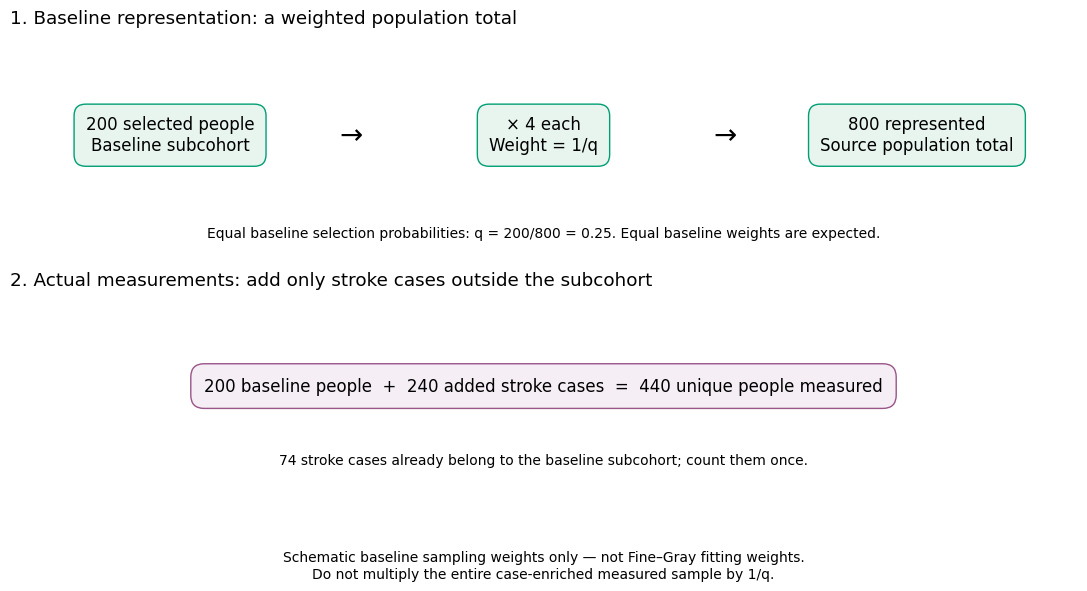

In [110]:
context(f'case-cohort baseline illustration; requested q={CC_FRACTION}; actual q={cc["q_actual"]:.3f}')
k, n_source = len(cc['baseline']), len(cohort)
added, measured = len(cc['added']), len(cc['measured'])
overlap = len(cc['baseline'] & cc['cases'])
fig, axes = plt.subplots(2, 1, figsize=(11, 6))
for ax in axes:
    ax.set(xlim=(0, 1), ylim=(0, 1))
    ax.axis('off')
axes[0].set_title('1. Baseline representation: a weighted population total', loc='left', pad=10)
if k:
    weight = 1/cc['q_actual']
    labels = [f'{k} selected people\nBaseline subcohort',
              f'× {weight:.3g} each\nWeight = 1/q',
              f'{k*weight:,.0f} represented\nSource population total']
    for x, label in zip([.15, .5, .85], labels):
        axes[0].text(x, .55, label, ha='center', va='center', fontsize=12,
                     bbox={'boxstyle': 'round,pad=.7', 'facecolor': '#e8f5ef', 'edgecolor': '#009E73'})
    for x in [.32, .67]:
        axes[0].text(x, .55, '→', ha='center', va='center', fontsize=20)
    axes[0].text(.5, .08, f'Equal baseline selection probabilities: q = {k}/{n_source} = '
                 f'{cc["q_actual"]:.3g}. Equal baseline weights are expected.', ha='center', fontsize=10)
else:
    axes[0].text(.5, .55, 'No baseline subcohort (q=0)\n1/q is undefined; no population representation.',
                 ha='center', va='center', fontsize=13)
axes[1].set_title('2. Actual measurements: add only stroke cases outside the subcohort', loc='left', pad=10)
axes[1].text(.5, .6, f'{k} baseline people  +  {added} added stroke cases  =  {measured} unique people measured',
             ha='center', va='center', fontsize=12,
             bbox={'boxstyle': 'round,pad=.8', 'facecolor': '#f5eef5', 'edgecolor': '#995588'})
axes[1].text(.5, .24, f'{overlap} stroke cases already belong to the baseline subcohort; count them once.',
             ha='center', fontsize=10)
fig.text(.5, .025, 'Schematic baseline sampling weights only — not Fine–Gray fitting weights.\n'
         'Do not multiply the entire case-enriched measured sample by 1/q.', ha='center', fontsize=10)
plt.tight_layout(rect=(0, .1, 1, 1)); plt.show()


## 4. Full-risk Fine–Gray: from a score to a probability
The network (or a linear model) outputs a log-risk score $\eta_i$. For a stroke at
$t_i$, let $w_{ij}$ be the contribution defined in Section 2. With distinct failure
times, minimize the average negative log pseudo-partial likelihood

$$L = \frac{1}{D}\sum_{i:\,event_i=1}
\left[\log\sum_j w_{ij}e^{\eta_j}-\eta_i\right].$$

$D$ is the number of strokes. At its failure time the case has weight 1; the
denominator includes it. We use `logsumexp` and **all training risk sets together**.
Independent shuffled minibatches would change this objective.

The baseline **subdistribution** cumulative hazard has jump
$\Delta A_0^*(t_i)=1/\sum_j w_{ij}e^{\eta_j}$, yielding
$F(t\mid x)=1-\exp[-A_0^*(t)e^{\eta(x)}]$. This differs from applying sigmoid to a score.
$\alpha_0(t)$ denotes baseline subdistribution hazard; $\lambda_0(t)$ denotes
baseline cause-specific hazard. Here 0 means the covariate reference, not time zero.

**Scope:** independent marginal censoring, fixed covariates, distinct event times,
no left truncation. Administrative censoring ties at the end are allowed. Event ties
are rejected; arbitrary jitter is not an inference strategy. The dense matrix is
deliberately simple and suitable for hundreds, not millions, of participants.


In [111]:
def fg_design(df):
    """Rows are stroke times; columns are people in df order."""
    failure_times = df.loc[df.event != 0, 'time'].to_numpy()
    if len(np.unique(failure_times)) != len(failure_times):
        raise ValueError('This educational fitter requires distinct event times.')
    cases = np.flatnonzero(df.event.to_numpy() == 1)
    cases = cases[np.argsort(df.time.to_numpy()[cases])]
    if not len(cases):
        raise ValueError('No strokes: no Fine–Gray objective to fit.')
    times = df.time.to_numpy()[cases]
    weights = np.vstack([risk_weights(df, t) for t in times])
    logw = np.full_like(weights, -np.inf)
    np.log(weights, out=logw, where=weights > 0)
    return cases, times, logw

def fg_loss_score(eta, cases, logw):
    """Mean negative pseudo log-likelihood and gradient with respect to all scores."""
    eta = np.asarray(eta, dtype=float).reshape(-1)
    logs = logw + eta[None, :]
    logden = logsumexp(logs, axis=1)
    loss = np.mean(logden-eta[cases])
    grad = np.exp(logs-logden[:, None]).sum(axis=0)
    np.add.at(grad, cases, -1.)
    return loss, grad/len(cases)

def fit_linear_fg(df, x):
    cases, times, logw = fg_design(df)
    def objective(beta):
        value, gradient = fg_loss_score(x@beta, cases, logw)
        return value, x.T@gradient
    result = minimize(objective, np.zeros(x.shape[1]), jac=True, method='BFGS',
                      options={'gtol': 1e-8, 'maxiter': 300})
    if np.linalg.norm(result.jac, ord=np.inf) > 1e-5:
        raise ValueError('Linear FG did not converge; increase events or review data.')
    jumps = np.exp(-logsumexp(logw + (x@result.x)[None, :], axis=1))
    return {'coef': result.x, 'times': times, 'baseline': np.cumsum(jumps),
            'jumps': jumps, 'loss': result.fun, 'evaluations': result.nfev}

def predict_fg(times, baseline, eta, query):
    index = np.searchsorted(times, np.asarray(query), side='right')
    a = np.r_[0., baseline][index]
    # Log cumulative hazard avoids overflowing exp(eta) for extreme scores.
    loga = np.full_like(a, -np.inf, dtype=float)
    np.log(a, out=loga, where=a > 0)
    z = np.asarray(eta).reshape(-1, 1) + loga[None, :]
    return -np.expm1(-np.exp(np.minimum(z, 700)))


### An analytical benchmark before fitting
Four people with outcomes: stroke at 1, death at 2, stroke at 3, death at 4;
binary predictor `[0, 0, 1, 1]`; no censoring. At time 1 all four contribute;
at time 3 the earlier death remains. The exact optimum is
`exp(beta)=1/sqrt(2)`. Baseline jumps are `1/(2+2r)` and `1/(1+2r)` for
`r=1/sqrt(2)`. We also check a censored example and numerical score derivatives.
This verifies a small mathematical case; an additional external reference check
is recorded in the README/tests. It does not establish sampled-model validity.


In [112]:
def verify_full_risk_math():
    tiny = pd.DataFrame({'time': [1., 2., 3., 4.], 'event': [1, 2, 1, 2]})
    x = np.array([[0.], [0.], [1.], [1.]])
    fit = fit_linear_fg(tiny, x)
    r = 1/np.sqrt(2)
    expected_jumps = np.array([1/(2+2*r), 1/(1+2*r)])
    np.testing.assert_allclose(fit['coef'], [np.log(r)], atol=1e-6)
    np.testing.assert_allclose(fit['jumps'], expected_jumps, atol=1e-7)
    expected_cif = 1-np.exp(-np.cumsum(expected_jumps)[None, :]*np.array([[1.], [r]]))
    np.testing.assert_allclose(predict_fg(fit['times'], fit['baseline'], [0, np.log(r)], [1., 3.]),
                               expected_cif, atol=1e-7)
    cases, times, logw = fg_design(tiny)
    np.testing.assert_allclose(fg_loss_score(np.zeros(4), cases, logw)[0], np.log(12)/2)
    eta = np.array([.1, -.2, .3, -.1])
    value, gradient = fg_loss_score(eta, cases, logw)
    eps = 1e-6
    numerical = np.array([(fg_loss_score(eta+eps*np.eye(4)[i], cases, logw)[0]-
                           fg_loss_score(eta-eps*np.eye(4)[i], cases, logw)[0])/(2*eps)
                          for i in range(4)])
    np.testing.assert_allclose(gradient, numerical, atol=1e-8)
    # At t=3: death at 1 retained with 2/3 after censoring at 2.
    censored = pd.DataFrame({'time': [1., 2., 3., 4.], 'event': [2, 0, 1, 1]})
    np.testing.assert_allclose(risk_weights(censored, 3.), [2/3, 0, 1, 1])
    c, _, lw = fg_design(censored)
    np.testing.assert_allclose(fg_loss_score(np.zeros(4), c, lw)[0],
                               (np.log(8/3)+np.log(5/3))/2)
    return True

FULL_RISK_MATH_CHECKED = verify_full_risk_math()
print('Analytical coefficient, baseline, CIF, zero-score loss and finite-difference checks passed.')


Analytical coefficient, baseline, CIF, zero-score loss and finite-difference checks passed.


,feature,FG coefficient,subdistribution HR
0,X1,0.385416,1.470226
1,X2,-0.233017,0.792140
2,X3,0.057588,1.059279
3,X4,0.071052,1.073637
4,X5,0.021787,1.022027
5,X6,-0.151397,0.859506
6,X7,0.055780,1.057365
7,X8,-0.007191,0.992835


Full-risk linear fit: 3.395s; no inference/standard errors supplied.
seed=2026; n=800; rates(stroke, death, censor)=(0.07, 0.05, 0.035); admin=10.0; Held-out profiles; solid=linear FG, dotted=conditional generating truth


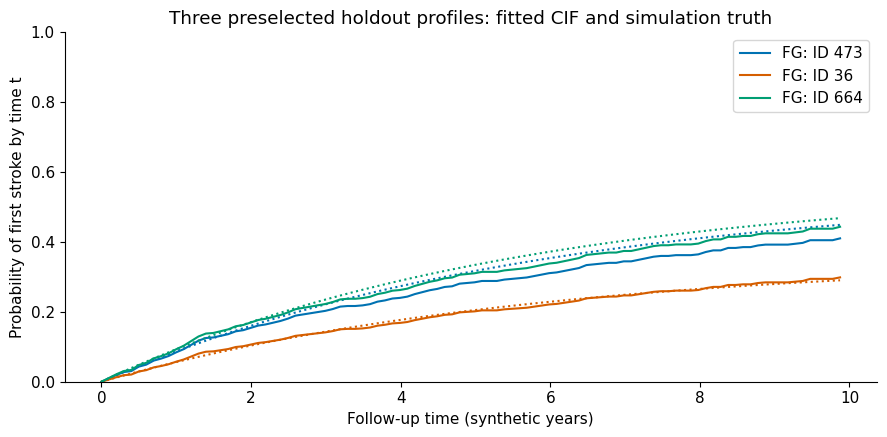

Holdout mean absolute CIF error against known simulation truth: 0.0311
Descriptive grid average; not an observed-outcome Brier score or clinical validation.


In [113]:
linear_fg = None
linear_seconds = np.nan
if (train.event == 1).sum() >= 15:
    try:
        start = time.perf_counter()
        linear_fg = fit_linear_fg(train, x_train)
        linear_seconds = time.perf_counter()-start
        display(pd.DataFrame({'feature': FEATURES, 'FG coefficient': linear_fg['coef'],
                              'subdistribution HR': np.exp(linear_fg['coef'])}))
        print(f'Full-risk linear fit: {linear_seconds:.3f}s; no inference/standard errors supplied.')
    except ValueError as exc:
        print('Linear FG skipped:', exc)
else:
    print('Linear FG skipped: fewer than 15 training strokes.')

context('Held-out profiles; solid=linear FG, dotted=conditional generating truth')
if linear_fg is not None:
    # Preselected holdout rows, not chosen by their realized outcomes or fit quality.
    horizon = min(ADMIN_TIME, float(linear_fg['times'][-1]))
    eval_grid = np.linspace(0, horizon, 100)
    fg_prediction = predict_fg(linear_fg['times'], linear_fg['baseline'], x_test@linear_fg['coef'], eval_grid)
    truth_test = population_truth.set_index('subject_id').loc[test.subject_id].reset_index()
    truth_prediction = true_cif(truth_test, eval_grid)
    fig, ax = plt.subplots()
    for k, color in enumerate(['#0072B2', '#D55E00', '#009E73']):
        ax.plot(eval_grid, fg_prediction[k], color=color, label=f'FG: ID {test.iloc[k].subject_id:g}')
        ax.plot(eval_grid, truth_prediction[k], ':', color=color)
    probability_axes(ax); ax.set_title('Three preselected holdout profiles: fitted CIF and simulation truth')
    ax.legend(); plt.tight_layout(); plt.show()
    linear_truth_mae = float(np.mean(np.abs(fg_prediction-truth_prediction)))
    print(f'Holdout mean absolute CIF error against known simulation truth: {linear_truth_mae:.4f}')
    print('Descriptive grid average; not an observed-outcome Brier score or clinical validation.')


### A tiny neural score: 361 parameters
The three hidden layers have 8, 16 and 8 units with `tanh` activation. The linear
output is a score. Parameters: `(8+1)×8 + (8+1)×16 + (16+1)×8 + (8+1)×1 = 361`.
The output bias is unidentifiable in the partial likelihood; a shared score shift
is absorbed by the estimated baseline. This is expected, not a probability intercept.

The optional code below first checks TensorFlow loss/gradients against NumPy,
including a censored case. Set `TRAIN_NEURAL=True` in the parameter cell only after
installing TensorFlow in a compatible environment. It uses one full-risk update per
epoch; no minibatches. Architecture, seed, optimizer, initial weights and budget are
recorded for future comparisons. Numerical verification is narrower than statistical
calibration, consistency or valid confidence intervals for a neural estimator.


seed=2026; n=800; rates(stroke, death, censor)=(0.07, 0.05, 0.035); admin=10.0; architecture=8→8→16→8→1; parameters=361; epochs=20; lr=0.01


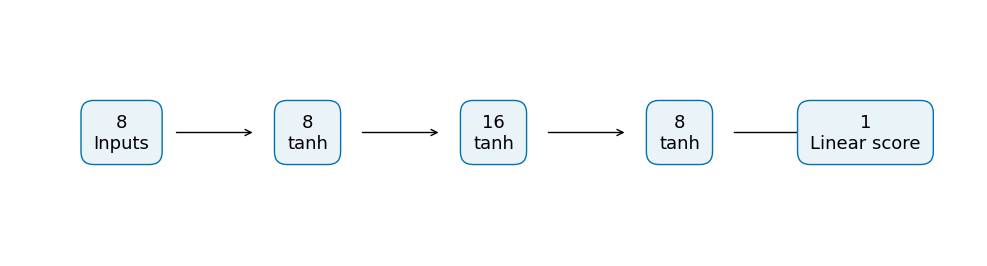

In [114]:
context(f'architecture=8→8→16→8→1; parameters=361; epochs={EPOCHS}; lr={LEARNING_RATE}')
fig, ax = plt.subplots(figsize=(10, 2.8))
for i, (size, label) in enumerate(zip([8, 8, 16, 8, 1], ['Inputs', 'tanh', 'tanh', 'tanh', 'Linear score'])):
    ax.text(i, .5, f'{size}\n{label}', ha='center', va='center', fontsize=13,
            bbox={'boxstyle': 'round,pad=.7', 'facecolor': '#e9f3f8', 'edgecolor': '#0072B2'})
    if i < 4:
        ax.annotate('', (i+.72, .5), (i+.28, .5), arrowprops={'arrowstyle': '->'})
ax.set(xlim=(-.6, 4.6), ylim=(0, 1)); ax.axis('off')
plt.tight_layout(); plt.show()


In [115]:
def build_model(tf):
    return tf.keras.Sequential([
        tf.keras.Input(shape=(8,), dtype='float64'),
        tf.keras.layers.Dense(8, activation='tanh', dtype='float64'),
        tf.keras.layers.Dense(16, activation='tanh', dtype='float64'),
        tf.keras.layers.Dense(8, activation='tanh', dtype='float64'),
        tf.keras.layers.Dense(1, dtype='float64')])

def tf_fg_loss(tf, eta, cases, logw):
    eta = tf.reshape(eta, [-1])
    return tf.reduce_mean(tf.reduce_logsumexp(logw+eta[None, :], axis=1)-tf.gather(eta, cases))

def verify_tensorflow(tf):
    for events in ([1, 2, 1, 2], [2, 0, 1, 1]):
        tiny = pd.DataFrame({'time': [1., 2., 3., 4.], 'event': events})
        cases, _, lw = fg_design(tiny)
        eta = tf.Variable([.1, -.2, .3, -.1], dtype=tf.float64)
        with tf.GradientTape() as tape:
            loss = tf_fg_loss(tf, eta, cases, tf.constant(lw))
        gradient = tape.gradient(loss, eta).numpy()
        expected, expected_grad = fg_loss_score(eta.numpy(), cases, lw)
        np.testing.assert_allclose(loss.numpy(), expected, atol=1e-10)
        np.testing.assert_allclose(gradient, expected_grad, atol=1e-10)
    return True


TensorFlow 2.20.0 | visible GPU: []


Model: "sequential_10"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ dense_40 (Dense)                │ (None, 8)              │            72 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_41 (Dense)                │ (None, 16)             │           144 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_42 (Dense)                │ (None, 8)              │           136 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_43 (Dense)                │ (None, 1)              │             9 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 361 (2.82 KB)

 Trainable params: 361 (2.82 KB)

 Non-trainable params: 0 (0.00 B)

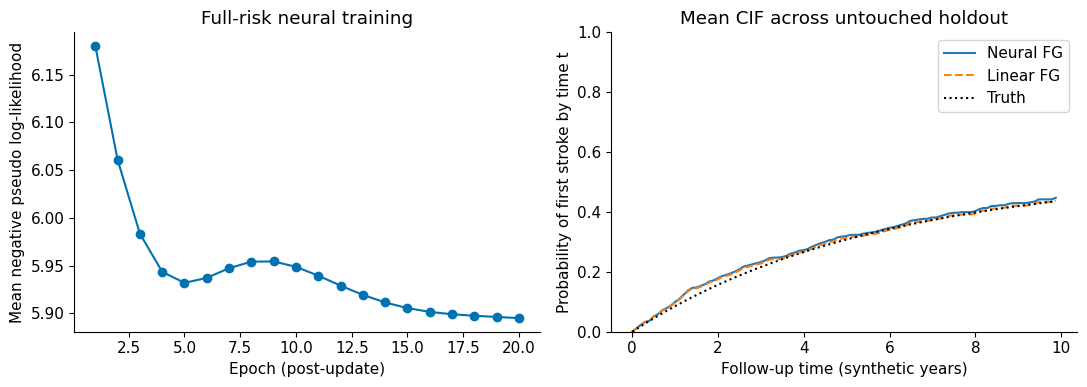

CPU training=0.655s; truth CIF MAE=0.0460


In [116]:
neural_model, neural_prediction = None, None
neural_seconds, neural_truth_mae = np.nan, np.nan
neural_status = 'skipped (opt-in)'
if TRAIN_NEURAL:
    try:
        import tensorflow as tf
    except (ImportError, OSError) as exc:
        print('Neural module skipped: TensorFlow unavailable:', exc)
        neural_status = 'skipped (TensorFlow unavailable)'
    else:
        tf.config.set_visible_devices([], 'GPU')
        print('TensorFlow', tf.__version__, '| visible GPU:', tf.config.get_visible_devices('GPU'))
        tf.keras.utils.set_random_seed(SEED+3)
        tf.config.experimental.enable_op_determinism()
        verify_tensorflow(tf)  # failure must stop training, not silently approve it
        neural_model = build_model(tf)
        assert neural_model.count_params() == 361
        neural_model.summary()
        initial_weights = [w.copy() for w in neural_model.get_weights()]
        if linear_fg is None:
            print('Neural training skipped: first resolve the full-risk data/fit check.')
            neural_status = 'skipped (full-risk fit unavailable)'
        else:
            cases, event_times, logw = fg_design(train)
            xt = tf.constant(x_train, dtype=tf.float64)
            lw = tf.constant(logw, dtype=tf.float64)
            optimizer = tf.keras.optimizers.Adam(learning_rate=LEARNING_RATE)
            history = []
            start = time.perf_counter()
            for epoch in range(EPOCHS):
                with tf.GradientTape() as tape:
                    loss = tf_fg_loss(tf, neural_model(xt), cases, lw)
                gradients = tape.gradient(loss, neural_model.trainable_variables)
                assert all(g is not None and np.isfinite(g.numpy()).all() for g in gradients)
                assert np.isfinite(loss.numpy())
                optimizer.apply_gradients(zip(gradients, neural_model.trainable_variables))
                history.append(float(tf_fg_loss(tf, neural_model(xt), cases, lw).numpy()))
            neural_seconds = time.perf_counter()-start
            eta_train = neural_model(xt).numpy().ravel()
            baseline = np.cumsum(np.exp(-logsumexp(logw+eta_train[None, :], axis=1)))
            eta_test = neural_model(tf.constant(x_test, dtype=tf.float64)).numpy().ravel()
            neural_prediction = predict_fg(event_times, baseline, eta_test, eval_grid)
            assert np.isfinite(neural_prediction).all()
            assert ((neural_prediction >= 0) & (neural_prediction <= 1)).all()
            assert (np.diff(neural_prediction, axis=1) >= -1e-12).all()
            neural_truth_mae = float(np.mean(np.abs(neural_prediction-truth_prediction)))
            neural_status = 'numerically checked educational full-risk fit'
            fig, axes = plt.subplots(1, 2, figsize=(11, 4))
            axes[0].plot(np.arange(1, EPOCHS+1), history, 'o-', color=COLORS[1])
            axes[0].set(xlabel='Epoch (post-update)', ylabel='Mean negative pseudo log-likelihood',
                        title='Full-risk neural training')
            axes[1].plot(eval_grid, neural_prediction.mean(axis=0), label='Neural FG')
            axes[1].plot(eval_grid, fg_prediction.mean(axis=0), '--', label='Linear FG')
            axes[1].plot(eval_grid, truth_prediction.mean(axis=0), ':', color='black', label='Truth')
            probability_axes(axes[1]); axes[1].set_title('Mean CIF across untouched holdout')
            axes[1].legend(); plt.tight_layout(); plt.show()
            print(f'CPU training={neural_seconds:.3f}s; truth CIF MAE={neural_truth_mae:.4f}')
else:
    print('Neural training is off. Set TRAIN_NEURAL=True and Run All in a TensorFlow runtime.')


## 5. Play with sampled neural scores

**PROTOTYPE / NOT VALIDATED — NOT A STATISTICAL FINE–GRAY ESTIMATOR**

These two small experiments use the instructor's conceptual Horvitz–Thompson denominator:

$$\widehat D(t)=\sum_{i=1}^n \frac{R_i}{\pi_i}\,q_i(t)\exp(f_\theta(X_i)).$$

Here $R_i$ is 1 when the person's biomarkers are measured; $\pi_i$ is their probability of ever being included; $q_i(t)$ is the constructed risk-set contribution, including the censoring retention weight; and $f_\theta$ is our 361-parameter neural log-risk score. We minimize the average of $\log\widehat D(t)-f_\theta(X_{case})$ over stroke times. All stroke cases are measured, so their inclusion probability is 1. Sampling weights and censoring weights remain separate inputs to this **illustrative** objective.

- **CC:** select one baseline subcohort, then add all stroke cases. Noncase inclusion probability is the actual baseline fraction (after rounding); case inclusion probability is 1.
- **NCC:** take the union of all cases and controls selected at stroke times. For a noncase, $\pi_i=1-\prod_k(1-p_{ik})$, where $p_{ik}=\min(m,|E_k|)/|E_k|$ when that person belongs to eligible controls $E_k$, otherwise 0. This uses independent draws across case times, conditional on the observed training outcomes. It is **not** just controls-per-case divided by one risk-set size.
- A death before the first stroke can have $\pi_i=0$ in ordinary NCC, despite contributing to later Fine–Gray risk sets. Such people cannot be represented by this design. We display that coverage gap and fit only a **restricted conceptual denominator**; we do not pretend it estimates the full cohort denominator. Zero controls or a zero-sized CC subcohort skips training.

A weighted risk-set sum does **not** validate its logarithm as a sampled Fine–Gray training method, neural inference, or baseline/CIF estimation. The full-risk construction is explained in [Kawaguchi et al., equations 2–3](https://journal.r-project.org/articles/RJ-2021-010/); our sampling substitution is a teaching experiment, not their validated estimator. Published design-specific NCC/CC estimators remain future work.

Every fit uses the same subject split, initial network weights, Adam learning rate, and epochs. Each sampled scaler is fitted **only on its measured training people**, so it may differ from the full-risk scaler. Full training outcomes (but no hidden biomarkers) supply censoring weights and inclusion probabilities. All measured features are used only after selection; holdout features are used only for evaluation.

**Read the outputs:** loss curves show optimization, not proof of statistical correctness. Holdout centered-score MAE measures disagreement with the full-risk neural score after subtracting each score vector's holdout mean; it is neither probability error nor accuracy against truth. The full-risk score is a reference, not ground truth. A separate panel below shows explicitly illustrative plug-in CIF curves; these are not validated population probability estimates.

**Try it:** keep the seeds fixed, change `NCC_CONTROLS` from 2 to 4 or `CC_FRACTION` from 0.25 to 0.10, restart and Run All. Compare measured people, loss curves, score differences, and coverage gaps. `CC_FRACTION=1` should recover the full-risk objective and training when settings are identical.


In [117]:
def prototype_design(outcomes, mode, m=2, q=.25, seed=2027):
    outcomes = outcomes[['subject_id', 'time', 'event']].reset_index(drop=True)
    if mode not in ('NCC', 'CC'):
        raise ValueError('Choose NCC or CC')
    sample = (sample_ncc(outcomes, m, seed) if mode == 'NCC'
              else sample_case_cohort(outcomes, q, seed))
    ids = outcomes.subject_id.to_numpy()
    if mode == 'NCC':
        never = np.ones(len(outcomes))
        for rec in sample['records']:
            eligible = np.isin(ids, rec['eligible'])
            if eligible.any():
                never[eligible] *= 1 - min(m, eligible.sum())/eligible.sum()
        pi = 1 - never
    else:
        pi = np.full(len(outcomes), sample['q_actual'])
    pi[outcomes.event.to_numpy() == 1] = 1.
    rows = np.flatnonzero(np.isin(ids, list(sample['measured'])))
    cases, times, full_logw = fg_design(outcomes)
    zero_support = (pi == 0) & np.isfinite(full_logw).any(axis=0)
    if (mode == 'NCC' and m == 0) or (mode == 'CC' and sample['q_actual'] == 0):
        raise ValueError('No noncase sampling support: cases-only setting; increase m or q.')
    assert np.all(pi[rows] > 0)
    local_cases = np.searchsorted(rows, cases)
    assert np.array_equal(rows[local_cases], cases)
    # q_i(t) is evaluated using all training outcomes, then restricted to measured IDs.
    logw = full_logw[:, rows] - np.log(pi[rows])[None, :]
    return {'ids': ids[rows], 'cases': local_cases, 'logw': logw,
            'pi': pi, 'times': times, 'zero_support': int(zero_support.sum())}


def fit_sampled_prototype(tf, measured, design, holdout_features, initial, epochs, rate):
    if epochs < 1 or rate <= 0:
        raise ValueError('Use positive epochs and learning rate.')
    selected = measured.set_index('subject_id').loc[design['ids'], FEATURES]
    if not np.isfinite(selected.to_numpy()).all():
        raise ValueError('Selected biomarkers must be available and finite.')
    local_scaler = StandardScaler().fit(selected)
    xt = tf.constant(local_scaler.transform(selected), dtype=tf.float64)
    model = build_model(tf)
    model.set_weights([w.copy() for w in initial])
    optimizer = tf.keras.optimizers.Adam(learning_rate=rate)
    lw = tf.constant(design['logw'], dtype=tf.float64)
    losses = []
    start = time.perf_counter()
    for _ in range(epochs):
        with tf.GradientTape() as tape:
            loss = tf_fg_loss(tf, model(xt), design['cases'], lw)
        gradients = tape.gradient(loss, model.trainable_variables)
        if not np.isfinite(loss.numpy()) or any(g is None or not np.isfinite(g.numpy()).all() for g in gradients):
            raise ValueError('Nonfinite prototype loss/gradient; lower the learning rate.')
        optimizer.apply_gradients(zip(gradients, model.trainable_variables))
        losses.append(float(tf_fg_loss(tf, model(xt), design['cases'], lw).numpy()))
    seconds = time.perf_counter() - start
    scores = model(tf.constant(local_scaler.transform(holdout_features), dtype=tf.float64)).numpy().ravel()
    if not np.isfinite(scores).all() or not np.isfinite(losses).all():
        raise ValueError('Nonfinite prototype scores/loss.')
    return {'model': model, 'scaler': local_scaler, 'history': losses,
            'seconds': seconds, 'scores': scores,
            'training_scores': model(xt).numpy().ravel()}


def prototype_cif(design, training_scores, prediction_scores, query):

    training_scores = np.asarray(training_scores, dtype=float).reshape(-1)
    prediction_scores = np.asarray(prediction_scores, dtype=float).reshape(-1)
    query = np.asarray(query, dtype=float)
    if len(training_scores) != design['logw'].shape[1]:
        raise ValueError('Training scores must follow measured-person order.')
    if not all(np.isfinite(a).all() for a in (training_scores, prediction_scores, query)):
        raise ValueError('Curve inputs must be finite.')
    logden = logsumexp(design['logw'] + training_scores[None, :], axis=1)
    if not np.isfinite(logden).all():
        raise ValueError('Every stroke time needs a finite positive denominator.')
    log_baseline = np.logaddexp.accumulate(-logden)
    index = np.searchsorted(design['times'], query, side='right')
    loga = np.r_[-np.inf, log_baseline][index]
    z = prediction_scores[:, None] + loga[None, :]
    curves = -np.expm1(-np.exp(np.minimum(z, 700)))
    if not np.isfinite(curves).all() or not ((curves >= 0) & (curves <= 1)).all():
        raise ValueError('Invalid illustrative curve values.')
    if np.all(np.diff(query) >= 0) and (np.diff(curves, axis=1) < -1e-12).any():
        raise ValueError('Illustrative curves must be nondecreasing.')
    return curves


NCC: 427 measured; 0 unrepresentable people with zero inclusion probability and a risk-set contribution.
CC: 319 measured; 0 unrepresentable people with zero inclusion probability and a risk-set contribution.
seed=2026; n=800; rates(stroke, death, censor)=(0.07, 0.05, 0.035); admin=10.0; PROTOTYPES NOT VALIDATED; m=2; q=0.25; epochs=20; lr=0.01


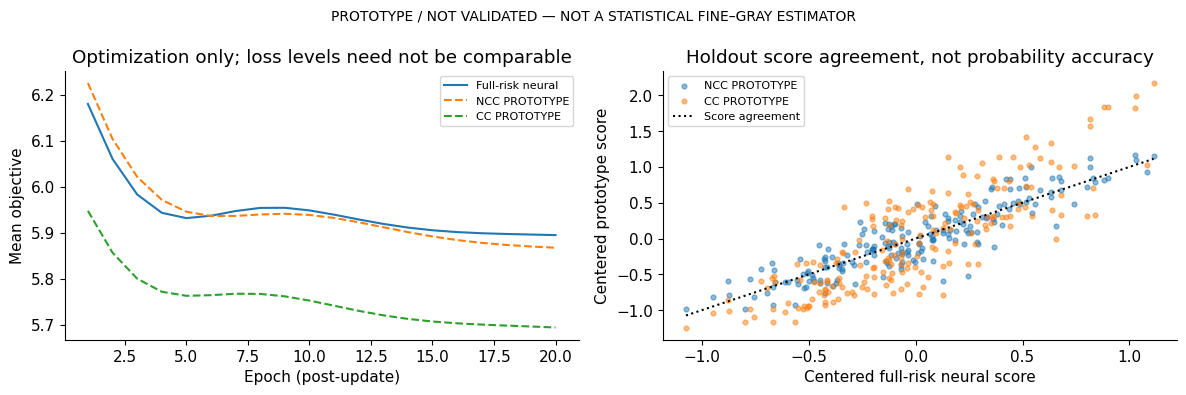

In [118]:
prototype_results = {}
prototype_rows = []
training_outcomes = train[['subject_id', 'time', 'event']]
for mode in ['NCC', 'CC']:
    sample = (sample_ncc(training_outcomes, NCC_CONTROLS, SELECTION_SEED) if mode == 'NCC'
              else sample_case_cohort(training_outcomes, CC_FRACTION, SELECTION_SEED))
    row = {'mode': mode + ' neural PROTOTYPE', 'status': 'skipped (prototype training off)',
           'training people measured': len(sample['measured']), 'CPU seconds': np.nan,
           'holdout truth CIF MAE': 'N/A - unvalidated CIF',
           'holdout centered-score MAE vs full neural': np.nan}
    if TRAIN_SAMPLED_PROTOTYPES and TRAIN_NEURAL and neural_prediction is not None:
        try:
            design = prototype_design(training_outcomes, mode, NCC_CONTROLS, CC_FRACTION, SELECTION_SEED)
            # Drop every unmeasured feature row before calling the trainer.
            measured = measured_view(train, sample['measured'])
            measured = measured.loc[measured.subject_id.isin(sample['measured'])].copy()
            result = fit_sampled_prototype(tf, measured, design, test[FEATURES],
                                          initial_weights, EPOCHS, LEARNING_RATE)
            reference_scores = neural_model(tf.constant(x_test, dtype=tf.float64)).numpy().ravel()
            centered_reference = reference_scores - reference_scores.mean()
            centered_sample = result['scores'] - result['scores'].mean()
            row.update({'status': 'PROTOTYPE / NOT VALIDATED', 'CPU seconds': result['seconds'],
                        'holdout centered-score MAE vs full neural': float(np.mean(np.abs(centered_sample-centered_reference)))})
            result['centered'] = centered_sample
            result['design'] = design
            prototype_results[mode] = result
            print(f'{mode}: {len(measured)} measured; {design["zero_support"]} unrepresentable people with zero inclusion probability and a risk-set contribution.')
            if design['zero_support']:
                print('COVERAGE GAP: this prototype denominator cannot represent the full Fine-Gray risk set.')
        except ValueError as exc:
            row['status'] = 'skipped: ' + str(exc)
    elif TRAIN_SAMPLED_PROTOTYPES and TRAIN_NEURAL:
        row['status'] = 'skipped (full-risk neural run unavailable)'
    prototype_rows.append(row)

if prototype_results:
    context(f'PROTOTYPES NOT VALIDATED; m={NCC_CONTROLS}; q={CC_FRACTION}; epochs={EPOCHS}; lr={LEARNING_RATE}')
    fig, axes = plt.subplots(1, 2, figsize=(12, 4))
    axes[0].plot(range(1, EPOCHS+1), history, label='Full-risk neural')
    for mode, result in prototype_results.items():
        axes[0].plot(range(1, EPOCHS+1), result['history'], '--', label=mode+' PROTOTYPE')
        axes[1].scatter(centered_reference, result['centered'], s=12, alpha=.5, label=mode+' PROTOTYPE')
    lo, hi = min(centered_reference), max(centered_reference)
    axes[1].plot([lo, hi], [lo, hi], ':', color='black', label='Score agreement')
    axes[0].set(xlabel='Epoch (post-update)', ylabel='Mean objective', title='Optimization only; loss levels need not be comparable')
    axes[1].set(xlabel='Centered full-risk neural score', ylabel='Centered prototype score', title='Holdout score agreement, not probability accuracy')
    for ax in axes: ax.legend(fontsize=8)
    fig.suptitle('PROTOTYPE / NOT VALIDATED — NOT A STATISTICAL FINE–GRAY ESTIMATOR', fontsize=10)
    plt.tight_layout(); plt.show()


### Illustrative NCC and CC CIF curves

**PROTOTYPE / NOT VALIDATED — the dashed curves are not validated population stroke probabilities.**

To show how sampling can change the curves, we use each prototype's own fitted scores and weighted training denominator to build an illustrative baseline:

$$\Delta\widehat A^*_{0,\mathrm{proto}}(t_k)=1/\widehat D(t_k),\qquad
\widetilde F_{\mathrm{proto}}(t\mid x)=1-\exp\{-\widehat A^*_{0,\mathrm{proto}}(t)\exp(f_\theta(x))\}.$$

There is one jump per distinct training stroke time. The baseline is calculated from **measured training scores and training outcomes only**, never borrowed from the full-risk fit or calibrated to holdout truth. The code checks its numerical construction against a hand calculation and full-coverage recovery in the tests; those checks do not establish validity under sampling. In particular, NCC's zero-inclusion coverage gap remains unresolved.

One plot compares cumulative incidence for the same evaluation group. Each line averages individual curves for people kept separate from training. The legend identifies NCC controls per stroke case and the CC baseline subcohort fraction (with stroke cases added). Blue is full-risk neural FG, orange is NCC, green is CC, and dotted black is simulation truth. The sampled curves remain conceptual prototypes as explained above.

**Try it:** change the controls-per-case or subcohort fraction, restart and Run All. Which illustrative curve changes most? A curve being close to truth in one run does not validate the estimator.


seed=2026; n=800; rates(stroke, death, censor)=(0.07, 0.05, 0.035); admin=10.0; Illustrative CIF; NCC controls=2; CC baseline fraction=25%; selection seed=2027


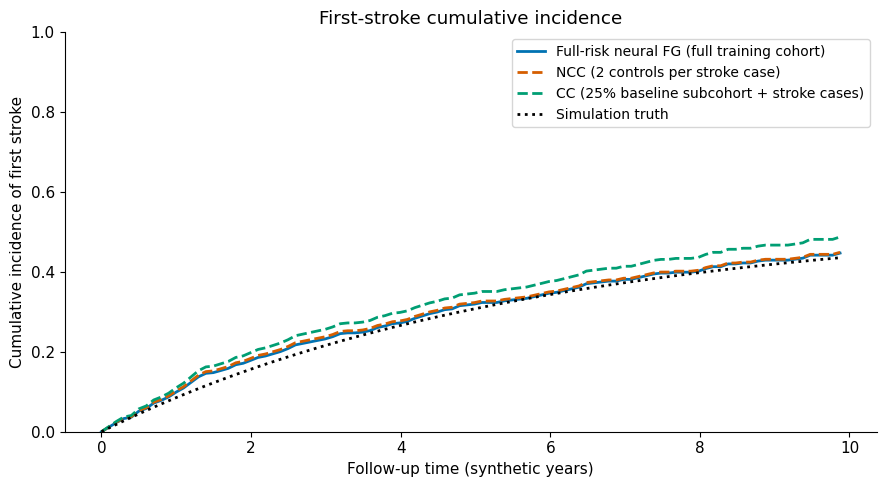

In [119]:
if prototype_results and neural_prediction is not None:
    context(f'Illustrative CIF; NCC controls={NCC_CONTROLS}; CC baseline fraction={CC_FRACTION:.0%}; selection seed={SELECTION_SEED}')
    fig, ax = plt.subplots(figsize=(9, 5))
    # Compare average individual curves for the same evaluation group.
    ax.plot(eval_grid, neural_prediction.mean(axis=0), color='#0072B2',
            linewidth=2, label='Full-risk neural FG (full training cohort)')
    for mode, result in prototype_results.items():
        try:
            curves = prototype_cif(result['design'], result['training_scores'], result['scores'], eval_grid)
        except ValueError as exc:
            print(f'{mode} illustrative CIF skipped: {exc}')
            continue
        result['illustrative_cif'] = curves
        color = {'NCC': '#D55E00', 'CC': '#009E73'}[mode]
        label = (f'NCC ({NCC_CONTROLS} controls per stroke case)' if mode == 'NCC'
                 else f'CC ({CC_FRACTION:.0%} baseline subcohort + stroke cases)')
        ax.plot(eval_grid, curves.mean(axis=0), '--', color=color, linewidth=2, label=label)
        gap = result['design']['zero_support']
        if gap:
            print(f'{mode}: {gap} contributing people have zero inclusion probability; this curve cannot represent the full risk set.')
    ax.plot(eval_grid, truth_prediction.mean(axis=0), ':', color='black',
            linewidth=2, label='Simulation truth')
    ax.set(title='First-stroke cumulative incidence',
           xlabel='Follow-up time (synthetic years)',
           ylabel='Cumulative incidence of first stroke', ylim=(0, 1))
    ax.legend(fontsize=10)
    plt.tight_layout(); plt.show()
else:
    print('Illustrative NCC/CC CIF panel skipped: enable both neural switches and complete prototype training.')


seed=2026; n=800; rates(stroke, death, censor)=(0.07, 0.05, 0.035); admin=10.0; budget experiments; selection seed=2027; cohort unchanged


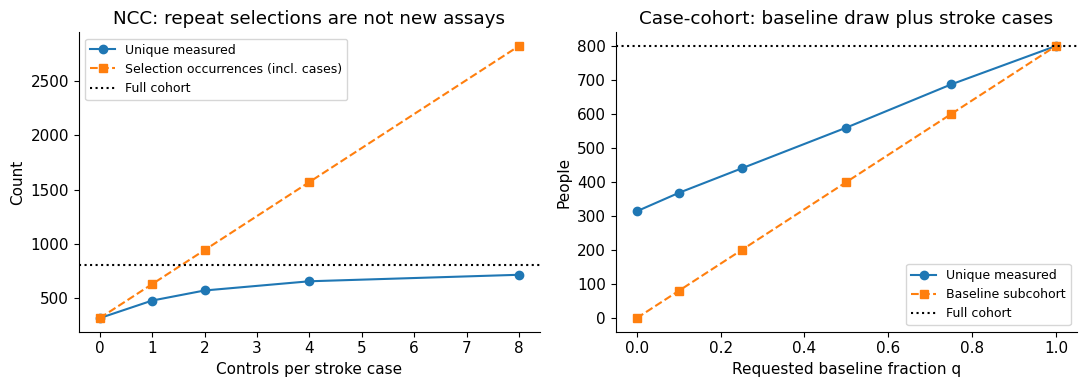

q=0 / m=0: cases only, descriptive cost endpoint; no valid sampled fit is implied.
CC fractions are nested by construction; NCC draws need not be nested across m.


,mode,status,training people measured,CPU seconds,holdout truth CIF MAE,holdout centered-score MAE vs full neural
0,Full-risk linear FG,reference-checked,600,3.394870,0.03112,N/A - skipped or not compared
1,Full-risk neural FG,numerically checked educational full-risk fit,600,0.655332,0.046025,0.0
2,NCC neural PROTOTYPE,PROTOTYPE / NOT VALIDATED,427,0.633617,N/A - unvalidated CIF,0.161826
3,CC neural PROTOTYPE,PROTOTYPE / NOT VALIDATED,319,0.613467,N/A - unvalidated CIF,0.348352


CPU seconds: training loop wall time on CPU, excluding selection, preprocessing and evaluation.
CIF MAE: probability error against synthetic truth, available for full-risk fits only.
Centered-score MAE: disagreement with the full-risk neural score; not probability error or ground-truth accuracy.
NCC/CC rows are conceptual prototypes, not validated sampled Fine-Gray estimators.
Dense full-risk matrix: 235 stroke times × 600 people = 141,000 cells per loss evaluation.


In [120]:
context(f'budget experiments; selection seed={SELECTION_SEED}; cohort unchanged')
m_values, q_values = [0, 1, 2, 4, 8], [0, .1, .25, .5, .75, 1.]
ncc_budgets = [sample_ncc(outcomes, m, SELECTION_SEED) for m in m_values]
cc_budgets = [sample_case_cohort(outcomes, q, SELECTION_SEED) for q in q_values]
fig, axes = plt.subplots(1, 2, figsize=(11, 4))
axes[0].plot(m_values, [len(s['measured']) for s in ncc_budgets], 'o-', label='Unique measured')
axes[0].plot(m_values, [len(s['cases'])+s['control_occurrences'] for s in ncc_budgets],
             's--', label='Selection occurrences (incl. cases)')
axes[0].axhline(N, color='black', linestyle=':', label='Full cohort')
axes[0].set(xlabel='Controls per stroke case', ylabel='Count', title='NCC: repeat selections are not new assays')
axes[1].plot(q_values, [len(s['measured']) for s in cc_budgets], 'o-', label='Unique measured')
axes[1].plot(q_values, [len(s['baseline']) for s in cc_budgets], 's--', label='Baseline subcohort')
axes[1].axhline(N, color='black', linestyle=':', label='Full cohort')
axes[1].set(xlabel='Requested baseline fraction q', ylabel='People', title='Case-cohort: baseline draw plus stroke cases')
for ax in axes: ax.legend(fontsize=9)
plt.tight_layout(); plt.show()
print('q=0 / m=0: cases only, descriptive cost endpoint; no valid sampled fit is implied.')
print('CC fractions are nested by construction; NCC draws need not be nested across m.')

comparison = pd.DataFrame([
    {'mode': 'Full-risk linear FG', 'status': 'reference-checked' if linear_fg else 'skipped',
     'training people measured': len(train), 'CPU seconds': linear_seconds,
     'holdout truth CIF MAE': linear_truth_mae if linear_fg else np.nan},
    {'mode': 'Full-risk neural FG', 'status': neural_status, 'training people measured': len(train),
     'CPU seconds': neural_seconds, 'holdout truth CIF MAE': neural_truth_mae},
    *prototype_rows])
comparison.loc[comparison['mode'] == 'Full-risk neural FG', 'holdout centered-score MAE vs full neural'] = 0.0 if neural_prediction is not None else np.nan
display(comparison.fillna('N/A - skipped or not compared'))
print('CPU seconds: training loop wall time on CPU, excluding selection, preprocessing and evaluation.')
print('CIF MAE: probability error against synthetic truth, available for full-risk fits only.')
print('Centered-score MAE: disagreement with the full-risk neural score; not probability error or ground-truth accuracy.')
print('NCC/CC rows are conceptual prototypes, not validated sampled Fine-Gray estimators.')
if linear_fg:
    d = int((train.event == 1).sum())
    print(f'Dense full-risk matrix: {d} stroke times × {len(train)} people = {d*len(train):,} cells per loss evaluation.')


### Optional: repeat sampling, not model fitting
Use five draws to see empirical variation in measurement costs. These are **not**
confidence intervals for coefficients or prediction. A smaller sample usually saves
measurements in expectation, but individual estimates are not guaranteed to be worse.


seed=2026; n=800; rates(stroke, death, censor)=(0.07, 0.05, 0.035); admin=10.0; repeats=5; m=2; q=0.25


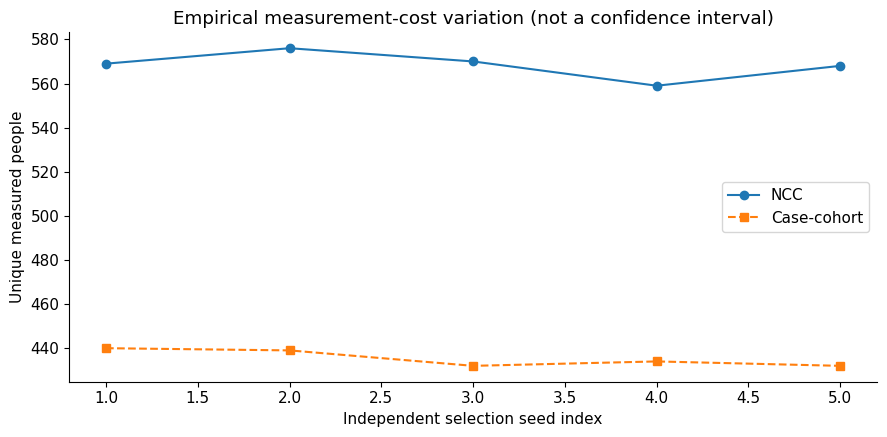

In [121]:
REPEATS = 5
context(f'repeats={REPEATS}; m={NCC_CONTROLS}; q={CC_FRACTION}')
rep_ncc = [len(sample_ncc(outcomes, NCC_CONTROLS, SELECTION_SEED+r)['measured']) for r in range(REPEATS)]
rep_cc = [len(sample_case_cohort(outcomes, CC_FRACTION, SELECTION_SEED+r)['measured']) for r in range(REPEATS)]
fig, ax = plt.subplots()
ax.plot(range(1, REPEATS+1), rep_ncc, 'o-', label='NCC')
ax.plot(range(1, REPEATS+1), rep_cc, 's--', label='Case-cohort')
ax.set(xlabel='Independent selection seed index', ylabel='Unique measured people',
       title='Empirical measurement-cost variation (not a confidence interval)')
ax.legend(); plt.tight_layout(); plt.show()


## 6. Check your understanding and restart safely
1. Which endpoint includes a fatal first stroke? **Stroke.**
2. Can a prior competing death remain in a Fine–Gray constructed risk set? **Yes,
   for mathematical bookkeeping, with the appropriate censoring contribution.**
3. Is 0.80 a stroke probability? **No, it is the example retention contribution.**
4. Can NCC select someone twice? **Across different case times, yes.**
5. Does case-cohort redraw at every event? **No.**
6. Does sigmoid of a neural score give a CIF? **No. Estimate the baseline first.**
7. Are the sampled neural fits complete? **Conceptual score prototypes run, but design-specific statistical validation is pending; sampled CIF curves are illustrative, not validated probability estimates.**

**Recovery:** restart the kernel/runtime and Run All. If imports fail, run the explicit
missing-package installation cell. If events are sparse, increase N or restore defaults.
If censoring support is poor, shorten follow-up or reduce censoring rather than clipping
weights silently. For slow sessions use `FAST_MODE=True`; training is optional.
Saved plots are executed examples under the printed parameters, not new results after
you edit a cell. Clear outputs or Run All after edits.

### References and verification boundaries
- [Fine & Gray (1999)](https://doi.org/10.1080/01621459.1999.10474144): original model.
- [Kawaguchi et al., R Journal, equations 2–3](https://journal.r-project.org/articles/RJ-2021-010/): full-risk weighted objective.
- [Putter et al.](https://pmc.ncbi.nlm.nih.gov/articles/PMC7216972/): cause-specific/subdistribution relation.
- [lifelines Aalen–Johansen](https://lifelines.readthedocs.io/en/latest/fitters/univariate/AalenJohansenFitter.html): API and tie limitation.
- [pycmprsk](https://pypi.org/project/pycmprsk/): optional external validation reference, not an attendee dependency.
- [Wolkewitz et al. (2014)](https://doi.org/10.1097/EDE.0000000000000029): NCC subdistribution sampling method; not implemented here.
- [Kim et al. (2020)](https://doi.org/10.1111/sjos.12461): case-cohort subdistribution model; not implemented here.
- [TensorFlow installation](https://www.tensorflow.org/install/pip) and [determinism](https://www.tensorflow.org/api_docs/python/tf/config/experimental/enable_op_determinism).
- [Colab FAQ](https://research.google.com/colaboratory/faq.html): free resources are variable and not guaranteed.

See README for the actual executed environment, tests, and outstanding Colab/TensorFlow
checks. Numerical checks do not validate clinical use or two-phase-design inference.
